# 七币种 DQN 门控策略回测

**币种**：BTC、ETH、BNB、PAXG、SOL、TRX、XLM（小时频 OHLCV）

**策略配置**（各币种一致）：
- 动态带：日频等价映射（`mid=MA(60)`、`half=4×ATR(14)`，shift(1)+ffill 到小时频）
- 门控：1h DQN，A1 账户状态（`position_ratio` + `cash_ratio`），R0 奖励，100k 步，seed 42
- 每格名义金额 ≈ 1000 USDT，初始底仓 50%，手续费 0.1%
- 训练集：2022-01-01 ~ 2025-12-31；测试集：2026-01-01 ~ 2026-09-30

**模型统一保存至 `models/`**，结果保存至 `data/multi_coin_dqn_results.csv`。

In [1]:
from pathlib import Path
import sys
import warnings

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({
    "font.family": "Noto Sans CJK SC",
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
warnings.filterwarnings("ignore")
print("项目根目录:", PROJECT_ROOT)

项目根目录: /home/nullwinters/Projects/CryptoGrid


In [2]:
# ================= 数据校验（duckdb） =================
coins = ["BTC", "ETH", "BNB", "PAXG", "SOL", "TRX", "XLM"]
rows = []
for c in coins:
    path = PROJECT_ROOT / "data" / f"{c.lower()}_usdt_1h.csv"
    q = f"""
    SELECT min(timestamp) AS t0, max(timestamp) AS t1, count(*) AS n,
           count(*) FILTER (WHERE timestamp >= '2022-01-01' AND timestamp <= '2025-12-31 23:00:00') AS train_n,
           count(*) FILTER (WHERE timestamp >= '2026-01-01' AND timestamp <= '2026-09-30 23:00:00') AS test_n
    FROM read_csv_auto('{path}')
    """
    r = duckdb.connect().execute(q).fetchdf().iloc[0].to_dict()
    r["coin"] = c
    rows.append(r)
df_check = pd.DataFrame(rows)[["coin", "n", "t0", "t1", "train_n", "test_n"]]
df_check["t0"] = df_check["t0"].astype(str)
df_check["t1"] = df_check["t1"].astype(str)
df_check

,coin,n,t0,t1,train_n,test_n
0,BTC,50626,2021-01-01,2026-10-11 23:00:00,35063,6552
1,ETH,50626,2021-01-01,2026-10-11 23:00:00,35063,6552
2,BNB,50626,2021-01-01,2026-10-11 23:00:00,35063,6552
3,PAXG,50626,2021-01-01,2026-10-11 23:00:00,35063,6552
4,SOL,50626,2021-01-01,2026-10-11 23:00:00,35063,6552
5,TRX,50626,2021-01-01,2026-10-11 23:00:00,35063,6552
6,XLM,50626,2021-01-01,2026-10-11 23:00:00,35063,6552


In [3]:
# ================= 结果加载（如缺失则运行训练脚本） =================
import subprocess, os
RESULT_CSV = PROJECT_ROOT / "data" / "multi_coin_dqn_results.csv"
if not RESULT_CSV.exists():
    print("结果 CSV 不存在，开始训练七币种模型（约 8~12 分钟）...")
    r = subprocess.run(
        [sys.executable, str(PROJECT_ROOT / "scripts" / "multi_coin_dqn.py")],
        capture_output=True, text=True, cwd=PROJECT_ROOT,
    )
    print(r.stdout[-2000:])
    if r.returncode != 0:
        print(r.stderr)
        raise RuntimeError("multi_coin_dqn.py 执行失败")

df = pd.read_csv(RESULT_CSV)
df["coin"] = df["coin"].astype(str)
print("模型目录:", PROJECT_ROOT / "models")
print("模型文件:", sorted([p.name for p in (PROJECT_ROOT / 'models').glob('*.zip')]))
df.head()

模型目录: /home/nullwinters/Projects/CryptoGrid/models
模型文件: ['dqn_gate_bnb_a1_1h.zip', 'dqn_gate_btc_a1_1h.zip', 'dqn_gate_eth_a1_1h.zip', 'dqn_gate_paxg_a1_1h.zip', 'dqn_gate_sol_a1_1h.zip', 'dqn_gate_trx_a1_1h.zip', 'dqn_gate_xlm_a1_1h.zip']


,coin,model,train_s,action0_ratio,rl_ret,rl_dd,rl_sharpe,rl_calmar,rl_end_nav,rl_trades,...,ma_gate_sharpe,ma_gate_calmar,ma_gate_end_nav,ma_gate_trades,ma_gate_reanchor,ma_gate_switch,bh_ret,bh_dd,bh_sharpe,bh_end_nav
0,BTC,/home/nullwinters/Projects/CryptoGrid/models/d...,83.7,0.582265,-0.071859,-0.155260,-0.868532,-0.611278,92767.654630,685,...,-0.343763,-0.360590,94309.851764,829,58,93,-0.047667,-0.403103,0.064395,95233.268758
1,ETH,/home/nullwinters/Projects/CryptoGrid/models/d...,78.5,0.606380,-0.127475,-0.248001,-0.903895,-0.672123,87208.852301,1165,...,-0.389474,-0.372758,92037.885976,1530,25,33,-0.098597,-0.550028,0.042769,90140.310959
2,BNB,/home/nullwinters/Projects/CryptoGrid/models/d...,81.2,0.614011,-0.124076,-0.180423,-1.558394,-0.899792,87548.592841,614,...,-0.585755,-0.494654,91381.779832,880,39,57,-0.112056,-0.432471,-0.158447,88794.367173
3,PAXG,/home/nullwinters/Projects/CryptoGrid/models/d...,79.5,0.323565,0.027373,-0.120481,0.359054,0.305199,102685.892037,367,...,0.317282,0.284654,102100.247381,697,37,55,-0.040551,-0.292250,-0.044431,95944.915713
4,SOL,/home/nullwinters/Projects/CryptoGrid/models/d...,82.4,0.628663,-0.100878,-0.253898,-0.683281,-0.522048,89867.216363,1506,...,-0.138627,-0.206297,95007.909200,1273,86,157,-0.056173,-0.587310,0.189042,94382.740711


In [4]:
# ================= 结果汇总表 =================
summary_cols = ["coin",
                "rl_ret", "rl_dd", "rl_sharpe", "rl_trades", "rl_switch",
                "ma_gate_ret", "ma_gate_dd", "ma_gate_sharpe", "ma_gate_trades",
                "no_gate_ret", "no_gate_dd", "no_gate_sharpe", "no_gate_trades",
                "bh_ret", "bh_dd", "bh_sharpe"]
summary = df[summary_cols].copy()
# 收益率与回撤转为百分比；Sharpe 保持原始数值
pct_cols = [c for c in summary.columns if c.endswith("_ret") or c.endswith("_dd")]
for col in pct_cols:
    summary[col] = summary[col] * 100
summary.columns = ["币种",
                   "DQN收益%", "DQN回撤%", "DQN Sharpe", "DQN成交", "DQN切换",
                   "MA收益%", "MA回撤%", "MA Sharpe", "MA成交",
                   "永撤收益%", "永撤回撤%", "永撤 Sharpe", "永撤成交",
                   "B&H收益%", "B&H回撤%", "B&H Sharpe"]
summary["DQN-MA收益差(pp)"] = summary["DQN收益%"] - summary["MA收益%"]
summary["DQN-MA回撤差(pp)"] = summary["DQN回撤%"] - summary["MA回撤%"]
summary = summary.round(3)
summary

,币种,DQN收益%,DQN回撤%,DQN Sharpe,DQN成交,DQN切换,MA收益%,MA回撤%,MA Sharpe,MA成交,永撤收益%,永撤回撤%,永撤 Sharpe,永撤成交,B&H收益%,B&H回撤%,B&H Sharpe,DQN-MA收益差(pp),DQN-MA回撤差(pp)
0,BTC,-7.186,-15.526,-0.869,685,468,-5.643,-20.725,-0.344,829,-3.888,-22.796,-0.138,2072,-4.767,-40.310,0.064,-1.543,5.199
1,ETH,-12.748,-24.800,-0.904,1165,488,-7.916,-28.012,-0.389,1530,-8.105,-31.418,-0.309,2470,-9.860,-55.003,0.043,-4.831,3.211
2,BNB,-12.408,-18.042,-1.558,614,456,-8.573,-22.833,-0.586,880,-8.018,-24.860,-0.443,2175,-11.206,-43.247,-0.158,-3.835,4.790
3,PAXG,2.737,-12.048,0.359,367,220,2.151,-10.143,0.317,697,-4.332,-17.249,-0.288,1420,-4.055,-29.225,-0.044,0.586,-1.905
4,SOL,-10.088,-25.390,-0.683,1506,566,-4.945,-31.780,-0.139,1273,-4.084,-33.539,-0.061,3155,-5.617,-58.731,0.189,-5.143,6.390
5,TRX,2.059,-6.748,0.636,284,244,3.941,-7.698,0.846,534,2.270,-8.381,0.468,1111,18.803,-17.012,1.227,-1.882,0.950
6,XLM,-5.306,-19.991,-0.403,1946,876,10.352,-25.243,0.527,2747,9.885,-23.822,0.528,5056,11.808,-48.025,0.593,-15.658,5.252


In [5]:
# ================= 汇总统计 =================
n = len(df)
print(f"币种数: {n}")
print(f"DQN 收益胜 MA 门控: {int((df.rl_ret > df.ma_gate_ret).sum())}/{n}")
print(f"DQN 收益胜 永不撤单: {int((df.rl_ret > df.no_gate_ret).sum())}/{n}")
print(f"DQN 回撤小于 MA 门控: {int((df.rl_dd > df.ma_gate_dd).sum())}/{n}")
print(f"DQN 回撤小于 永不撤单: {int((df.rl_dd > df.no_gate_dd).sum())}/{n}")
print(f"DQN Sharpe 胜 MA 门控: {int((df.rl_sharpe > df.ma_gate_sharpe).sum())}/{n}")
print(f"DQN 收益胜 B&H: {int((df.rl_ret > df.bh_ret).sum())}/{n}")
print()
print("各币种 DQN 相对 MA 门控：")
for _, row in df.iterrows():
    d_ret = (row.rl_ret - row.ma_gate_ret) * 100
    d_dd = (row.rl_dd - row.ma_gate_dd) * 100
    print(f"  {row.coin}: Δ收益 {d_ret:+.2f}pp, Δ回撤 {d_dd:+.2f}pp (正=回撤更小)")

币种数: 7
DQN 收益胜 MA 门控: 1/7
DQN 收益胜 永不撤单: 1/7
DQN 回撤小于 MA 门控: 6/7
DQN 回撤小于 永不撤单: 7/7
DQN Sharpe 胜 MA 门控: 1/7
DQN 收益胜 B&H: 1/7

各币种 DQN 相对 MA 门控：
  BTC: Δ收益 -1.54pp, Δ回撤 +5.20pp (正=回撤更小)
  ETH: Δ收益 -4.83pp, Δ回撤 +3.21pp (正=回撤更小)
  BNB: Δ收益 -3.84pp, Δ回撤 +4.79pp (正=回撤更小)
  PAXG: Δ收益 +0.59pp, Δ回撤 -1.91pp (正=回撤更小)
  SOL: Δ收益 -5.14pp, Δ回撤 +6.39pp (正=回撤更小)
  TRX: Δ收益 -1.88pp, Δ回撤 +0.95pp (正=回撤更小)
  XLM: Δ收益 -15.66pp, Δ回撤 +5.25pp (正=回撤更小)


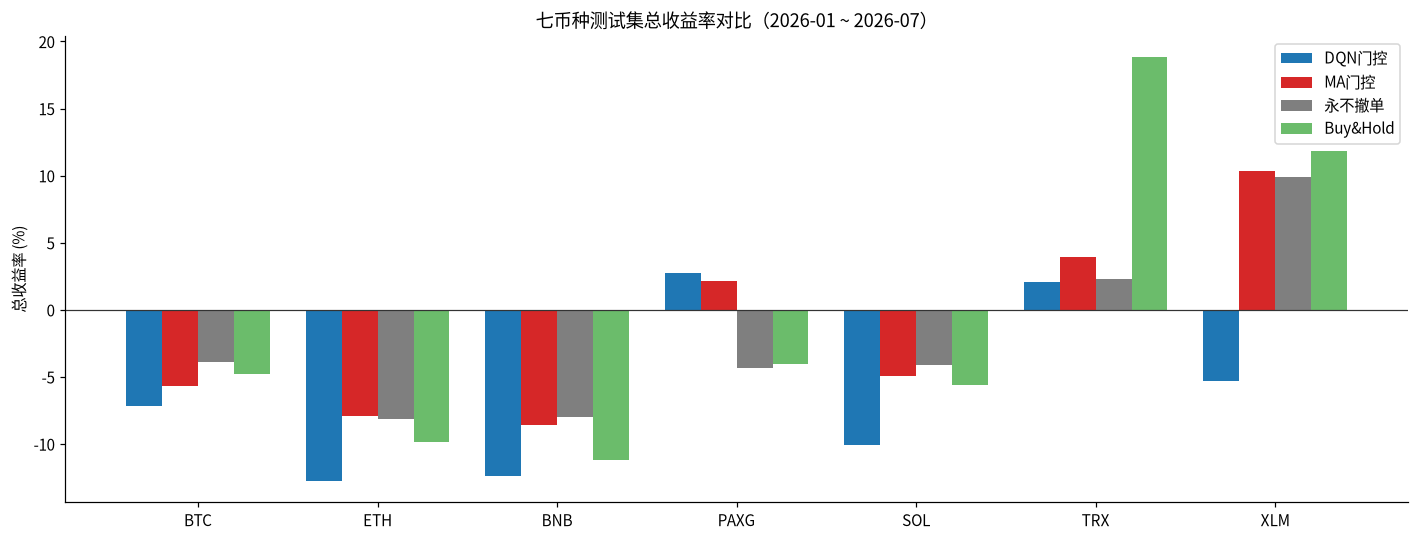

In [6]:
# ================= 图1：各币种收益对比 =================
coins = df["coin"].tolist()
x = np.arange(len(coins)); w = 0.2
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - 1.5*w, df["rl_ret"]*100, w, color="#1f77b4", label="DQN门控")
ax.bar(x - 0.5*w, df["ma_gate_ret"]*100, w, color="#d62728", label="MA门控")
ax.bar(x + 0.5*w, df["no_gate_ret"]*100, w, color="#7f7f7f", label="永不撤单")
ax.bar(x + 1.5*w, df["bh_ret"]*100, w, color="#2ca02c", ls="--", alpha=0.7, label="Buy&Hold")
ax.axhline(0, color="#333", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(coins)
ax.set_ylabel("总收益率 (%)")
ax.set_title("七币种测试集总收益率对比（2026-01 ~ 2026-07）")
ax.legend()
plt.tight_layout()
plt.show()

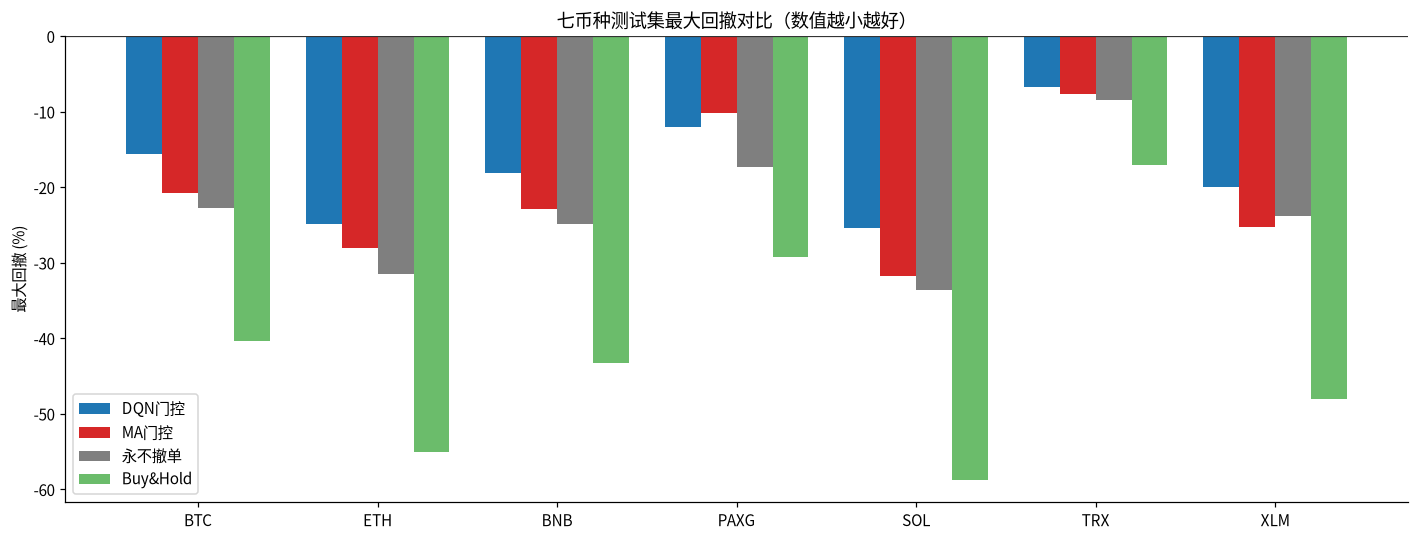

In [7]:
# ================= 图2：各币种最大回撤对比 =================
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - 1.5*w, df["rl_dd"]*100, w, color="#1f77b4", label="DQN门控")
ax.bar(x - 0.5*w, df["ma_gate_dd"]*100, w, color="#d62728", label="MA门控")
ax.bar(x + 0.5*w, df["no_gate_dd"]*100, w, color="#7f7f7f", label="永不撤单")
ax.bar(x + 1.5*w, df["bh_dd"]*100, w, color="#2ca02c", ls="--", alpha=0.7, label="Buy&Hold")
ax.axhline(0, color="#333", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(coins)
ax.set_ylabel("最大回撤 (%)")
ax.set_title("七币种测试集最大回撤对比（数值越小越好）")
ax.legend()
plt.tight_layout()
plt.show()

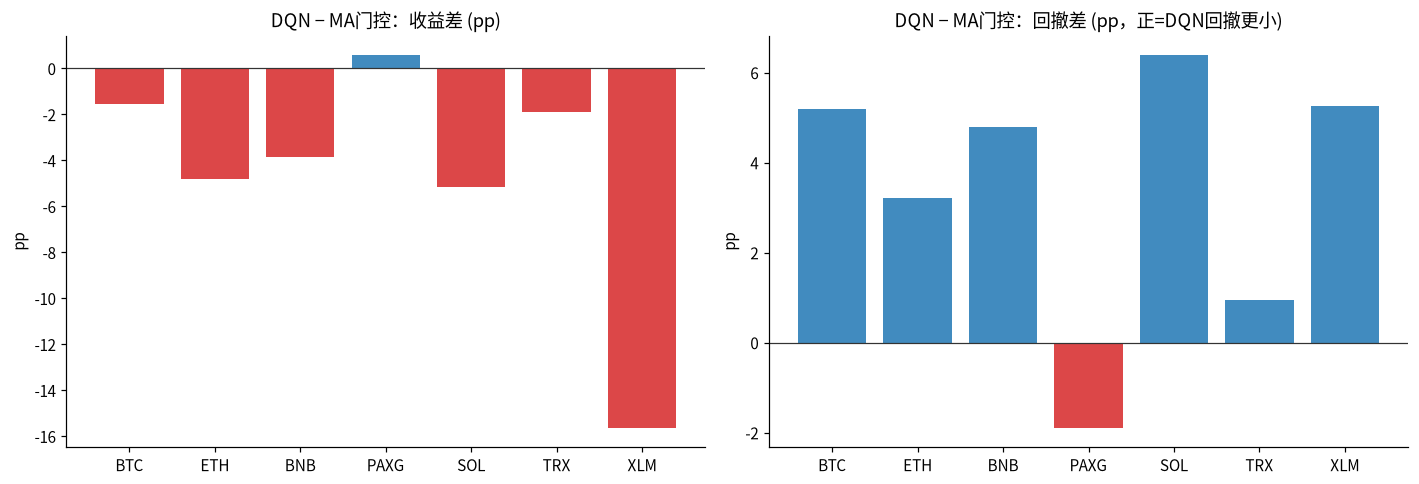

In [8]:
# ================= 图3：DQN 相对 MA 门控的收益/回撤改进 =================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
d_ret = (df["rl_ret"] - df["ma_gate_ret"]) * 100
d_dd = (df["rl_dd"] - df["ma_gate_dd"]) * 100
colors = ["#d62728" if v < 0 else "#1f77b4" for v in d_ret]
axes[0].bar(coins, d_ret, color=colors, alpha=0.85)
axes[0].axhline(0, color="#333", lw=0.8)
axes[0].set_title("DQN − MA门控：收益差 (pp)")
axes[0].set_ylabel("pp")
colors2 = ["#d62728" if v < 0 else "#1f77b4" for v in d_dd]
axes[1].bar(coins, d_dd, color=colors2, alpha=0.85)
axes[1].axhline(0, color="#333", lw=0.8)
axes[1].set_title("DQN − MA门控：回撤差 (pp，正=DQN回撤更小)")
axes[1].set_ylabel("pp")
plt.tight_layout()
plt.show()

## 初步结论

1. **DQN 门控的回撤控制优势在七币种上复现**：相对永不撤单 7/7 回撤更小，相对 MA 门控 6/7 回撤更小（仅 PAXG 例外，-12.05% vs -10.14%）。
2. **收益方面，本窗口 DQN 门控明显落后**：相对 MA 门控、永不撤单、Buy&Hold 均只胜 1/7（仅 PAXG 相对 MA 高 0.59pp）。测试期扩到 2026-01-01 ~ 2026-09-30 后纳入三季度反弹行情，门控的防守姿态变成机会成本，XLM 最典型：DQN -5.31% vs MA +10.35%，差距 15.66pp；SOL、ETH 分别落后 MA 5.14pp、4.83pp。
3. **风险资产（BTC/ETH/BNB/SOL/XLM）九个月整体仍为负收益**：BTC -7.19%、ETH -12.75%、BNB -12.41%、SOL -10.09%、XLM -5.31%，除 PAXG（+2.74%）和 TRX（+2.06%）外 Sharpe 均为负，说明门控只能减亏，不能逆势。
4. **PAXG（黄金代币，低波动）仍是收益最好且唯一相对 MA 占优的品种**：DQN 收益 +2.74%、回撤 -12.05%、Sharpe 0.359；但相对永不撤单（-4.33%）的优势主要来自门控在回撤段的表现，其绝对回撤仍略大于 MA 门控。
5. **TRX/XLM 抖单问题依旧**：XLM 切换 876 次、SOL 566 次、ETH 488 次，低价格或低流动性品种的网格与门控噪声更大。
6. **普遍规律**：DQN 门控更适合作为“回撤控制开关”使用，在下跌段减亏有效；在趋势上涨或超低波动行情中，永不撤单网格的进攻性更强，单一测试窗口的收益胜负对行情结构高度敏感。

**下一步**：对表现较差的币种做分行情分析；对 XLM/TRX 加入最短持有期；对 PAXG 单独调低 DQN 保守度（如减小切换惩罚）；并在多币种上做多种子验证。

